In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
%pip install openpyxl


   ---------------------------------------- 0/2 [et-xmlfile]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [open


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
df = pd.read_excel("Gold_data.xlsx", sheet_name="Gold_data", header=None)

In [10]:
 df.head(12)

,0,1,2,3,4,5,6,7
0,src_file,tab,period,row_no,c1,c2,c3,c4
1,17--monthly-average-price-of-gold-and-silver-i...,Monthly Average Price of Gold and Silver in Mu...,full-history,1,NaN,NaN,NaN,NaN
2,17--monthly-average-price-of-gold-and-silver-i...,Monthly Average Price of Gold and Silver in Mu...,full-history,2,Monthly Average Price of Gold and Silver in Mu...,NaN,NaN,NaN
3,17--monthly-average-price-of-gold-and-silver-i...,Monthly Average Price of Gold and Silver in Mu...,full-history,3,NaN,NaN,NaN,NaN
4,17--monthly-average-price-of-gold-and-silver-i...,Monthly Average Price of Gold and Silver in Mu...,full-history,4,Month/Year,1 Standard Gold (Rupees per 10 grams),2 Silver (Rupees per kilogram),NaN
5,17--monthly-average-price-of-gold-and-silver-i...,Monthly Average Price of Gold and Silver in Mu...,full-history,5,2026-08-01 00:00:00,"1,53,234","2,29,655",NaN
6,17--monthly-average-price-of-gold-and-silver-i...,Monthly Average Price of Gold and Silver in Mu...,full-history,6,2026-07-01 00:00:00,"1,42,606","2,22,396",NaN
7,17--monthly-average-price-of-gold-and-silver-i...,Monthly Average Price of Gold and Silver in Mu...,full-history,7,2026-06-01 00:00:00,"1,48,095","2,41,743",NaN
8,17--monthly-average-price-of-gold-and-silver-i...,Monthly Average Price of Gold and Silver in Mu...,full-history,8,2026-05-01 00:00:00,"1,54,756","2,63,202",NaN
9,17--monthly-average-price-of-gold-and-silver-i...,Monthly Average Price of Gold and Silver in Mu...,full-history,9,2026-04-01 00:00:00,"1,49,927","2,41,672",NaN


In [8]:
df.iloc[4:12, 4:7]

,4,5,6
4,Month/Year,1 Standard Gold (Rupees per 10 grams),2 Silver (Rupees per kilogram)
5,2026-08-01 00:00:00,"1,53,234","2,29,655"
6,2026-07-01 00:00:00,"1,42,606","2,22,396"
7,2026-06-01 00:00:00,"1,48,095","2,41,743"
8,2026-05-01 00:00:00,"1,54,756","2,63,202"
9,2026-04-01 00:00:00,"1,49,927","2,41,672"
10,2026-03-01 00:00:00,"1,53,299","2,50,291"
11,2026-02-01 00:00:00,"1,54,039","2,56,061"


In [9]:
df.shape

(445, 8)

# Data Cleaning 

In [12]:
# creating a new dataframe called gold
gold = df.iloc[5:,4:7].copy()
gold.columns=["Date","Gold_Price_INR_Per_10g","Silver_Price_INR_Per_kg"]


In [13]:
gold.head()

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg
5,2026-08-01 00:00:00,"1,53,234","2,29,655"
6,2026-07-01 00:00:00,"1,42,606","2,22,396"
7,2026-06-01 00:00:00,"1,48,095","2,41,743"
8,2026-05-01 00:00:00,"1,54,756","2,63,202"
9,2026-04-01 00:00:00,"1,49,927","2,41,672"


In [14]:
gold.tail()

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg
440,1990-05-01 00:00:00,3431,6734
441,1990-04-01 00:00:00,3417,6756
442,NaN,NaN,NaN
443,Source: Bombay Bullion Association Ltd.,NaN,NaN
444,NaN,NaN,NaN


In [16]:
gold.shape

(440, 3)

In [17]:
gold.dtypes

Date                       object
Gold_Price_INR_Per_10g     object
Silver_Price_INR_Per_kg    object
dtype: object

In [18]:
gold.isnull().sum()

Date                       2
Gold_Price_INR_Per_10g     3
Silver_Price_INR_Per_kg    3
dtype: int64

In [19]:
gold.tail(3)

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg
442,NaN,NaN,NaN
443,Source: Bombay Bullion Association Ltd.,NaN,NaN
444,NaN,NaN,NaN


In [20]:
type(gold["Gold_Price_INR_Per_10g"].iloc[0])

str

In [25]:
# converting the DATE column (into proper date format)

gold["Date"]=pd.to_datetime(gold["Date"],errors="coerce")

In [24]:
# converting gold and silver prices to proper numeric format 

gold["Gold_Price_INR_Per_10g"]=pd.to_numeric(
    gold["Gold_Price_INR_Per_10g"].astype("string").str.replace(",","",regex=False),
    errors="coerce")

gold["Silver_Price_INR_Per_kg"]=pd.to_numeric(
    gold["Silver_Price_INR_Per_kg"].astype("string").str.replace(",","",regex=False), errors="coerce")
    

In [26]:
gold.dtypes

Date                       datetime64[ns]
Gold_Price_INR_Per_10g              Int64
Silver_Price_INR_Per_kg             Int64
dtype: object

In [28]:
gold.isnull().sum()

Date                       3
Gold_Price_INR_Per_10g     3
Silver_Price_INR_Per_kg    3
dtype: int64

In [30]:
gold = gold.dropna(subset=[
    "Date",
    "Gold_Price_INR_Per_10g",
    "Silver_Price_INR_Per_kg"
])

In [31]:
gold.shape

(437, 3)

In [32]:
gold.isnull().sum()

Date                       0
Gold_Price_INR_Per_10g     0
Silver_Price_INR_Per_kg    0
dtype: int64

In [33]:
gold.tail()

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg
437,1990-08-01,3415,6939
438,1990-07-01,3285,6804
439,1990-06-01,3314,6697
440,1990-05-01,3431,6734
441,1990-04-01,3417,6756


In [35]:
# checking redundant date in column
gold["Date"].duplicated().sum()

np.int64(0)

In [37]:
# resting the dataframe index

gold= gold.reset_index(drop=True)

In [38]:
gold.head()

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg
0,2026-08-01,153234,229655
1,2026-07-01,142606,222396
2,2026-06-01,148095,241743
3,2026-05-01,154756,263202
4,2026-04-01,149927,241672


In [39]:
# filtering as we require 10 years of data 

gold_10yr = gold[(gold["Date"] >= "2016-01-01" ) & (gold["Date"] <= "2025-12-31")].copy()

In [40]:
gold_10yr.shape

(120, 3)

In [41]:
gold_10yr.head()

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg
8,2025-12-01,131172,198182
9,2025-11-01,122962,155010
10,2025-10-01,121908,155904
11,2025-09-01,109591,129257
12,2025-08-01,99696,114032


In [42]:
gold_10yr.tail()

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg
123,2016-05-01,29639,40693
124,2016-04-01,28818,38656
125,2016-03-01,28794,37500
126,2016-02-01,28252,36917
127,2016-01-01,25998,34287


In [45]:
gold_10yr["Date"].min()

Timestamp('2016-01-01 00:00:00')

In [46]:
gold_10yr["Date"].max()

Timestamp('2025-12-01 00:00:00')

In [48]:
gold_10yr["Date"].dt.to_period("M").nunique()

120

In [50]:
# sorting data from oldest to newest

gold_10yr = gold_10yr.sort_values("Date").reset_index(drop=True)

In [51]:
gold_10yr.head()

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg
0,2016-01-01,25998,34287
1,2016-02-01,28252,36917
2,2016-03-01,28794,37500
3,2016-04-01,28818,38656
4,2016-05-01,29639,40693


In [52]:
# adding additional columns 
#year
gold_10yr["Year"]=gold_10yr["Date"].dt.year

#Month_Number
gold_10yr["Month_Number"]=gold_10yr["Date"].dt.month

#Month_Name
gold_10yr["Month_Name"]=gold_10yr["Date"].dt.month_name()



In [53]:
gold_10yr.head()

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg,Year,Month_Number,Month_Name
0,2016-01-01,25998,34287,2016,1,January
1,2016-02-01,28252,36917,2016,2,February
2,2016-03-01,28794,37500,2016,3,March
3,2016-04-01,28818,38656,2016,4,April
4,2016-05-01,29639,40693,2016,5,May


# EXPLORATORY DATA ANALYSIS 

In [55]:
gold_10yr["Gold_Price_INR_Per_10g"].describe()

count           120.0
mean     50066.308333
std      22367.568814
min           25998.0
25%           31004.0
50%           47539.5
75%          58810.25
max          131172.0
Name: Gold_Price_INR_Per_10g, dtype: Float64

In [56]:
# AVG Gold Price for each YEAR
gold_10yr.groupby("Year")["Gold_Price_INR_Per_10g"].mean().round(2)

Year
2016     29354.75
2017     28975.17
2018     30625.25
2019     34852.83
2020     47231.33
2021     47366.17
2022      50944.0
2023     59027.08
2024     70725.58
2025    101560.92
Name: Gold_Price_INR_Per_10g, dtype: Float64

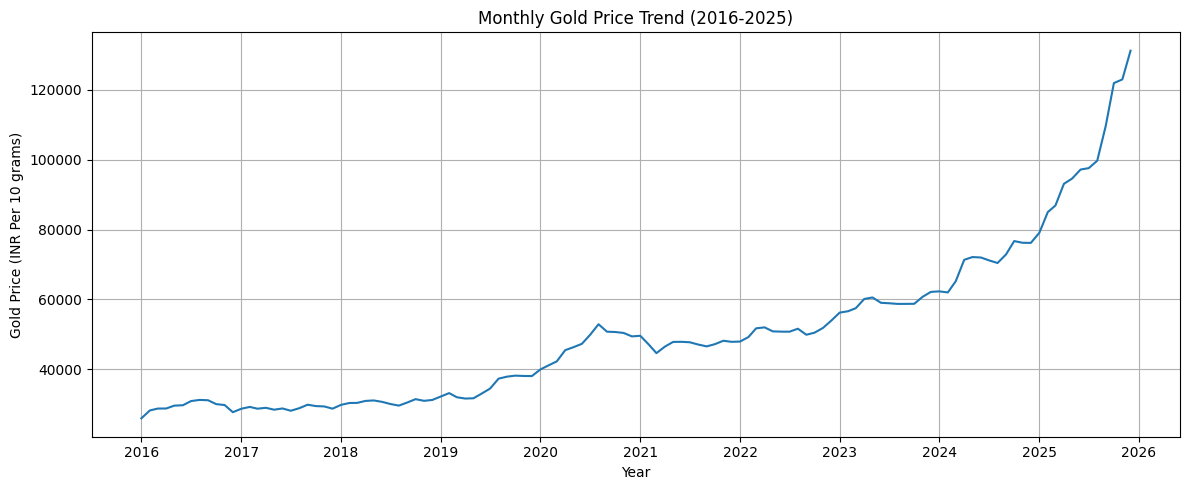

In [70]:
# line chart 

plt.figure(figsize=(12,5))

plt.plot(
    gold_10yr["Date"],
    gold_10yr["Gold_Price_INR_Per_10g"],
     )

plt.title("Monthly Gold Price Trend (2016-2025)")
plt.xlabel("Year")
plt.ylabel("Gold Price (INR Per 10 grams)")


plt.grid(True)
plt.tight_layout()

plt.show()

In [72]:
gold_10yr.head(12)

,Date,Gold_Price_INR_Per_10g,Silver_Price_INR_Per_kg,Year,Month_Number,Month_Name
0,2016-01-01,25998,34287,2016,1,January
1,2016-02-01,28252,36917,2016,2,February
2,2016-03-01,28794,37500,2016,3,March
3,2016-04-01,28818,38656,2016,4,April
4,2016-05-01,29639,40693,2016,5,May
5,2016-06-01,29745,41196,2016,6,June
6,2016-07-01,30942,46943,2016,7,July
7,2016-08-01,31270,46614,2016,8,August
8,2016-09-01,31178,46234,2016,9,September
9,2016-10-01,30071,43230,2016,10,October


In [77]:
# long term trend 
gold_10yr["Trend"]=(gold_10yr["Gold_Price_INR_Per_10g"].rolling(window=13, center=True).mean())

In [78]:
gold_10yr[[
    "Date",
    "Gold_Price_INR_Per_10g",
    "Trend"
]].head(15)

,Date,Gold_Price_INR_Per_10g,Trend
0,2016-01-01,25998,NaN
1,2016-02-01,28252,NaN
2,2016-03-01,28794,NaN
3,2016-04-01,28818,NaN
4,2016-05-01,29639,NaN
5,2016-06-01,29745,NaN
6,2016-07-01,30942,29307.923077
7,2016-08-01,31270,29559.230769
8,2016-09-01,31178,29598.153846
9,2016-10-01,30071,29614.769231


In [79]:
# seasonal devaiation
gold_10yr["Seasonal_Deviation_%"] = (
    (gold_10yr["Gold_Price_INR_Per_10g"] - gold_10yr["Trend"])/ gold_10yr["Trend"]) * 100

In [80]:
gold_10yr[[
    "Date",
    "Gold_Price_INR_Per_10g",
    "Trend",
    "Seasonal_Deviation_%"
]].head(15)

,Date,Gold_Price_INR_Per_10g,Trend,Seasonal_Deviation_%
0,2016-01-01,25998,NaN,<NA>
1,2016-02-01,28252,NaN,<NA>
2,2016-03-01,28794,NaN,<NA>
3,2016-04-01,28818,NaN,<NA>
4,2016-05-01,29639,NaN,<NA>
5,2016-06-01,29745,NaN,<NA>
6,2016-07-01,30942,29307.923077,5.575547
7,2016-08-01,31270,29559.230769,5.787597
8,2016-09-01,31178,29598.153846,5.337651
9,2016-10-01,30071,29614.769231,1.540551


In [81]:
gold_10yr[[
    "Date",
    "Gold_Price_INR_Per_10g",
    "Trend",
    "Seasonal_Deviation_%"
]].tail(10)

,Date,Gold_Price_INR_Per_10g,Trend,Seasonal_Deviation_%
110,2025-03-01,86890,88053.538462,-1.321399
111,2025-04-01,93091,91825.076923,1.378625
112,2025-05-01,94590,95382.692308,-0.831065
113,2025-06-01,97176,99609.692308,-2.443228
114,2025-07-01,97581,NaN,<NA>
115,2025-08-01,99696,NaN,<NA>
116,2025-09-01,109591,NaN,<NA>
117,2025-10-01,121908,NaN,<NA>
118,2025-11-01,122962,NaN,<NA>
119,2025-12-01,131172,NaN,<NA>


In [82]:
# calculating avg seasonal deviation by month

seasonal_data = gold_10yr.dropna(
    subset=["Seasonal_Deviation_%"]
).copy()

In [85]:
seasonal_data.shape

(108, 8)

In [87]:
monthly_seasonality = seasonal_data.groupby(["Month_Number", "Month_Name"])["Seasonal_Deviation_%"].agg(
    Average_Deviation="mean",
    Median_Deviation="median",
    Std_Deviation="std",
    Observations="count"
).reset_index()

In [88]:
monthly_seasonality = monthly_seasonality.sort_values("Month_Number").reset_index(drop=True)

In [89]:
monthly_seasonality.round(2)

,Month_Number,Month_Name,Average_Deviation,Median_Deviation,Std_Deviation,Observations
0,1,January,-1.14,-2.24,2.39,9
1,2,February,-0.67,-0.06,2.58,9
2,3,March,-1.11,-1.32,3.36,9
3,4,April,1.39,1.76,3.75,9
4,5,May,0.64,1.22,3.54,9
5,6,June,0.0,0.72,2.12,9
6,7,July,0.26,-0.6,3.11,9
7,8,August,0.9,-0.73,4.82,9
8,9,September,0.14,-1.91,3.97,9
9,10,October,-0.44,0.26,3.06,9


# pattern recognition 

In [90]:
# year-wise monthly deviation table
year_month_table = seasonal_data.pivot_table(
    index="Year",
    columns="Month_Name",
    values="Seasonal_Deviation_%"
)

In [91]:
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

year_month_table = year_month_table[month_order]

In [92]:
year_month_table.round(2)

Month_Name,January,February,March,April,May,June,July,August,September,October,November,December
Year,,,,,,,,,,,,
2016,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,5.58,5.79,5.34,1.54,0.7,-6.0
2017,-2.24,0.06,-1.31,-0.01,-1.69,-0.2,-3.01,-0.95,2.19,0.26,-0.65,-3.36
2018,-0.03,1.39,1.06,2.52,2.56,0.74,-2.12,-4.4,-1.91,0.83,-0.89,-0.61
2019,1.56,2.86,-2.72,-5.55,-6.74,-4.21,-2.06,3.95,3.53,1.44,-1.75,-4.77
2020,-3.16,-3.53,-3.32,1.76,1.5,1.69,5.2,10.33,5.3,4.42,3.48,1.21
2021,1.48,-3.22,-7.35,-2.92,0.29,0.77,0.74,-0.58,-2.42,-2.26,-0.93,-2.01
2022,-2.31,-0.28,4.32,4.24,1.22,0.19,-1.11,-0.73,-5.21,-5.24,-3.87,-1.19
2023,1.87,1.47,2.03,5.42,4.74,0.72,-0.6,-1.65,-2.72,-4.36,-2.54,-1.7
2024,-2.9,-4.69,-1.4,5.65,4.72,2.78,-0.25,-3.65,-2.86,-0.59,-3.46,-5.8


In [93]:
seasonal_data["Below_Trend"] = (
    seasonal_data["Seasonal_Deviation_%"] < 0
)

monthly_consistency = seasonal_data.groupby(
    ["Month_Number", "Month_Name"]
)["Below_Trend"].agg(
    Years_Below_Trend="sum",
    Observations="count",
    Percentage_Below_Trend="mean"
).reset_index()

monthly_consistency["Percentage_Below_Trend"] *= 100

monthly_consistency.round(2)

,Month_Number,Month_Name,Years_Below_Trend,Observations,Percentage_Below_Trend
0,1,January,6,9,66.67
1,2,February,5,9,55.56
2,3,March,6,9,66.67
3,4,April,3,9,33.33
4,5,May,3,9,33.33
5,6,June,3,9,33.33
6,7,July,6,9,66.67
7,8,August,6,9,66.67
8,9,September,5,9,55.56
9,10,October,4,9,44.44


In [94]:
# calculating the 12 month moving avg
gold_10yr["MA_12"] = (
    gold_10yr["Gold_Price_INR_Per_10g"]
    .rolling(window=12)
    .mean()
)

In [95]:
# center the 12 month moving avg
gold_10yr["Trend_12M"] = (
    gold_10yr["MA_12"]
    .rolling(window=2)
    .mean()
    .shift(-6)
)

In [96]:
gold_10yr["Seasonal_Deviation_12M_%"] = (
    (
        gold_10yr["Gold_Price_INR_Per_10g"]
        - gold_10yr["Trend_12M"]
    )
    / gold_10yr["Trend_12M"]
) * 100

In [97]:
gold_10yr[[
    "Date",
    "Gold_Price_INR_Per_10g",
    "Trend_12M",
    "Seasonal_Deviation_12M_%"
]].head(15)

,Date,Gold_Price_INR_Per_10g,Trend_12M,Seasonal_Deviation_12M_%
0,2016-01-01,25998,NaN,<NA>
1,2016-02-01,28252,NaN,<NA>
2,2016-03-01,28794,NaN,<NA>
3,2016-04-01,28818,NaN,<NA>
4,2016-05-01,29639,NaN,<NA>
5,2016-06-01,29745,NaN,<NA>
6,2016-07-01,30942,29469.250000,4.997582
7,2016-08-01,31270,29625.958333,5.549328
8,2016-09-01,31178,29666.666667,5.094382
9,2016-10-01,30071,29673.166667,1.340717


In [98]:
gold_10yr[[
    "Date",
    "Gold_Price_INR_Per_10g",
    "Trend_12M",
    "Seasonal_Deviation_12M_%"
]].tail(15)

,Date,Gold_Price_INR_Per_10g,Trend_12M,Seasonal_Deviation_12M_%
105,2024-10-01,76713,76747.666667,-0.04517
106,2024-11-01,76221,78589.041667,-3.013196
107,2024-12-01,76195,80573.083333,-5.43368
108,2025-01-01,79079,82721.166667,-4.402944
109,2025-02-01,84995,85039.791667,-0.052671
110,2025-03-01,86890,87788.458333,-1.023436
111,2025-04-01,93091,91201.291667,2.072019
112,2025-05-01,94590,95031.958333,-0.465063
113,2025-06-01,97176,99270.208333,-2.109604
114,2025-07-01,97581,NaN,<NA>


In [99]:
gold_10yr["Seasonal_Deviation_12M_%"].notna().sum()

np.int64(108)

In [100]:
#revised seasonality dataset
seasonal_data_12m = gold_10yr.dropna(
    subset=["Seasonal_Deviation_12M_%"]
).copy()

In [101]:
seasonal_data_12m.shape

(108, 11)

In [102]:
monthly_seasonality_12m = seasonal_data_12m.groupby(
    ["Month_Number", "Month_Name"]
)["Seasonal_Deviation_12M_%"].agg(
    Average_Deviation="mean",
    Median_Deviation="median",
    Std_Deviation="std",
    Observations="count"
).reset_index()

monthly_seasonality_12m = monthly_seasonality_12m.sort_values(
    "Month_Number"
).reset_index(drop=True)

monthly_seasonality_12m.round(2)

,Month_Number,Month_Name,Average_Deviation,Median_Deviation,Std_Deviation,Observations
0,1,January,-1.1,-2.2,2.34,9
1,2,February,-0.57,-0.05,2.54,9
2,3,March,-1.04,-1.02,3.24,9
3,4,April,1.49,2.07,3.59,9
4,5,May,0.68,1.18,3.43,9
5,6,June,-0.04,0.61,2.01,9
6,7,July,0.22,-0.6,2.86,9
7,8,August,0.9,-0.58,4.59,9
8,9,September,0.11,-1.89,3.73,9
9,10,October,-0.28,0.42,2.8,9


In [103]:
seasonal_data_12m["Below_Trend"] = (
    seasonal_data_12m["Seasonal_Deviation_12M_%"] < 0
)

monthly_consistency_12m = seasonal_data_12m.groupby(
    ["Month_Number", "Month_Name"]
)["Below_Trend"].agg(
    Years_Below_Trend="sum",
    Observations="count",
    Percentage_Below_Trend="mean"
).reset_index()

monthly_consistency_12m["Percentage_Below_Trend"] *= 100

monthly_consistency_12m.round(2)

,Month_Number,Month_Name,Years_Below_Trend,Observations,Percentage_Below_Trend
0,1,January,6,9,66.67
1,2,February,5,9,55.56
2,3,March,6,9,66.67
3,4,April,2,9,22.22
4,5,May,3,9,33.33
5,6,June,3,9,33.33
6,7,July,6,9,66.67
7,8,August,6,9,66.67
8,9,September,5,9,55.56
9,10,October,4,9,44.44


In [110]:
heatmap_data = seasonal_data_12m.pivot(
    index="Year",
    columns="Month_Number",
    values="Seasonal_Deviation_12M_%"
)

heatmap_data = heatmap_data.reindex(columns=range(1, 13))

# Convert Pandas nullable values into standard NumPy float values
heatmap_data = pd.DataFrame(
    heatmap_data.to_numpy(dtype="float64", na_value=np.nan),
    index=heatmap_data.index,
    columns=heatmap_data.columns
)

print(heatmap_data.dtypes)
print(heatmap_data.head())

Month_Number
1     float64
2     float64
3     float64
4     float64
5     float64
6     float64
7     float64
8     float64
9     float64
10    float64
11    float64
12    float64
dtype: object
Month_Number        1         2         3         4         5         6   \
Year                                                                       
2016               NaN       NaN       NaN       NaN       NaN       NaN   
2017         -2.196213  0.301751 -0.918617  0.215043 -1.510415 -0.380619   
2018         -0.227952  1.189355  1.090971  2.599252  2.521214  0.607494   
2019          1.714038  3.182151 -2.394116 -5.240591 -6.615633 -4.185375   
2020         -2.978341 -3.069733 -3.201899  1.708591  1.246289  1.190519   

Month_Number        7         8         9         10        11        12  
Year                                                                      
2016          4.997582  5.549328  5.094382  1.340717  0.551759 -6.063264  
2017         -2.933474 -0.760505  2.286703  0.4

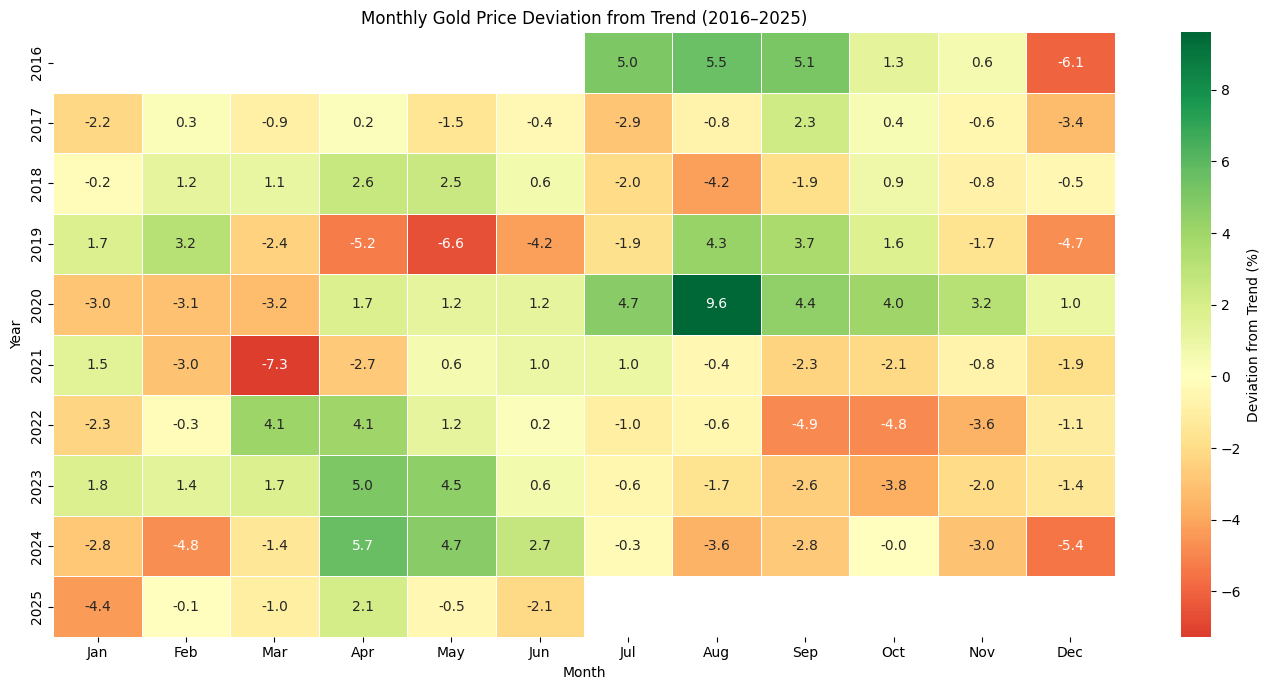

In [111]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    mask=np.isnan(heatmap_data.to_numpy()),
    cbar_kws={"label": "Deviation from Trend (%)"}
)

plt.title("Monthly Gold Price Deviation from Trend (2016–2025)")
plt.xlabel("Month")
plt.ylabel("Year")

plt.xticks(
    np.arange(12) + 0.5,
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
    rotation=0
)

plt.tight_layout()
plt.show()

# festival and wedding season comparison

In [112]:
# comparison table 
festival_periods = {
    "Akshaya Tritiya Window": [4, 5],
    "Dhanteras Window": [10, 11],
    "Wedding Season Window": [11, 12, 1, 2, 4, 5]
}

festival_results = []

for period, months in festival_periods.items():

    period_data = seasonal_data_12m[
        seasonal_data_12m["Month_Number"].isin(months)
    ]

    festival_results.append({
        "Period": period,
        "Average_Deviation": period_data[
            "Seasonal_Deviation_12M_%"
        ].mean(),
        "Median_Deviation": period_data[
            "Seasonal_Deviation_12M_%"
        ].median(),
        "Std_Deviation": period_data[
            "Seasonal_Deviation_12M_%"
        ].std(),
        "Below_Trend_Count": (
            period_data["Seasonal_Deviation_12M_%"] < 0
        ).sum(),
        "Observations": len(period_data),
        "Percentage_Below_Trend": (
            period_data["Seasonal_Deviation_12M_%"] < 0
        ).mean() * 100
    })

festival_comparison = pd.DataFrame(festival_results)

festival_comparison.round(2)

,Period,Average_Deviation,Median_Deviation,Std_Deviation,Below_Trend_Count,Observations,Percentage_Below_Trend
0,Akshaya Tritiya Window,1.08,1.48,3.43,5,18,27.78
1,Dhanteras Window,-0.63,-0.70,2.39,11,18,61.11
2,Wedding Season Window,-0.52,-0.47,2.96,31,54,57.41


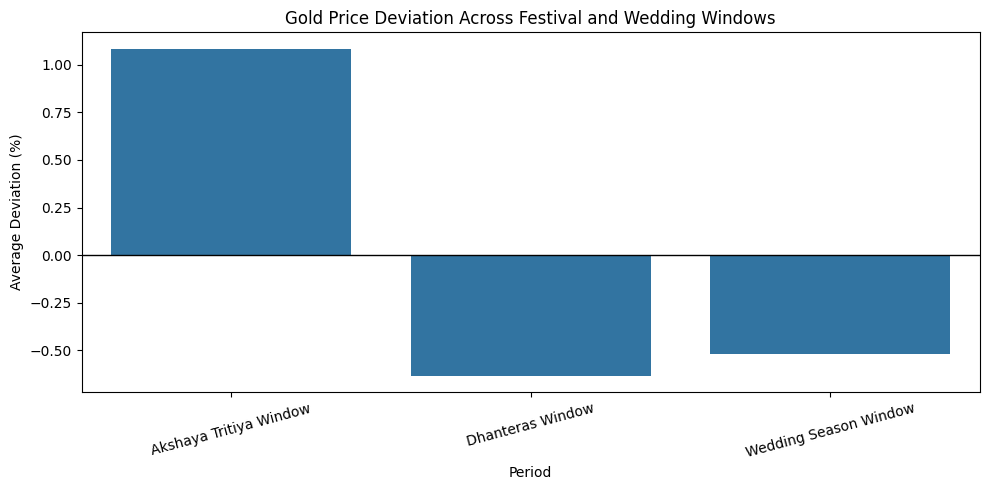

In [113]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=festival_comparison,
    x="Period",
    y="Average_Deviation"
)

plt.axhline(0, color="black", linewidth=1)

plt.title("Gold Price Deviation Across Festival and Wedding Windows")
plt.xlabel("Period")
plt.ylabel("Average Deviation (%)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [114]:
# Main Dataset
final_monthly_analysis = monthly_seasonality_12m.merge(
    monthly_consistency_12m[
        ["Month_Number", "Years_Below_Trend",
         "Percentage_Below_Trend"]
    ],
    on="Month_Number",
    how="left"
)

final_monthly_analysis = final_monthly_analysis.sort_values(
    "Month_Number"
).reset_index(drop=True)

final_monthly_analysis.round(2)

,Month_Number,Month_Name,Average_Deviation,Median_Deviation,Std_Deviation,Observations,Years_Below_Trend,Percentage_Below_Trend
0,1,January,-1.1,-2.2,2.34,9,6,66.67
1,2,February,-0.57,-0.05,2.54,9,5,55.56
2,3,March,-1.04,-1.02,3.24,9,6,66.67
3,4,April,1.49,2.07,3.59,9,2,22.22
4,5,May,0.68,1.18,3.43,9,3,33.33
5,6,June,-0.04,0.61,2.01,9,3,33.33
6,7,July,0.22,-0.6,2.86,9,6,66.67
7,8,August,0.9,-0.58,4.59,9,6,66.67
8,9,September,0.11,-1.89,3.73,9,5,55.56
9,10,October,-0.28,0.42,2.8,9,4,44.44


In [115]:
print("Monthly data:", gold_10yr.shape)
print("Monthly seasonality:", final_monthly_analysis.shape)
print("Festival comparison:", festival_comparison.shape)

Monthly data: (120, 11)
Monthly seasonality: (12, 8)
Festival comparison: (3, 7)


In [116]:
gold_10yr.to_csv("Gold_Cleaned_Data.csv", index=False)

final_monthly_analysis.to_csv(
    "Gold_Monthly_Seasonality.csv",
    index=False
)

festival_comparison.to_csv(
    "Gold_Festival_Window_Comparison.csv",
    index=False
)

print("All 3 CSV files exported successfully!")

All 3 CSV files exported successfully!


In [117]:
import os

files = [
    "Gold_Cleaned_Data.csv",
    "Gold_Monthly_Seasonality.csv",
    "Gold_Festival_Window_Comparison.csv"
]

for file in files:
    print(file, "—", os.path.getsize(file), "bytes")

Gold_Cleaned_Data.csv — 14263 bytes
Gold_Monthly_Seasonality.csv — 1215 bytes
Gold_Festival_Window_Comparison.csv — 422 bytes
